# 01: Exploring the simulated fleet

Week 2 exit check: **can you see each failure mode coming in the raw signals, and do healthy
GPUs ever look the same?** This notebook simulates a fleet, checks data quality, and plots the
warning signs of each failure mode against healthy GPUs.

The failure rate is raised to 0.5% of GPUs per day so a 30-day run has 30+ failures to look at.
Everything here can be regenerated with `gpufleet simulate --failure-rate 0.005 --out data/explore`
and `gpufleet plots data/explore`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from gpufleet.clean import quality_report
from gpufleet.config import SimConfig
from gpufleet.explore import (
    Dataset,
    fig_collection,
    fig_failure_signatures,
    fig_lookalikes,
    fig_stragglers,
    hourly_signals,
    scrape_signals,
    warning_time,
)
from gpufleet.simulator import simulate

warnings.simplefilter("ignore")
pd.set_option("display.width", 120)


In [2]:
cfg = SimConfig(failure_rate_per_gpu_day=0.005, seed=0)
result = simulate(cfg)
ds = Dataset.from_result(result)
print(f"{len(ds.telemetry):,} rows, {ds.telemetry['gpu_uuid'].nunique()} GPUs, {cfg.days:g} days")
ds.failures.groupby(["mode", "observed"]).size().unstack(fill_value=0)

2,173,385 rows, 284 GPUs, 30 days


observed,False,True
mode,,
memory,2,8
nvlink,0,6
power,0,4
sudden,0,9
thermal,0,5


## 1. Data quality

Real collection is messy, and the simulator now is too: node reboots and driver upgrades take
nodes offline and reset DCGM counters, exporters go down while the node keeps running, single
scrapes get lost, and node clocks are off by up to a few tens of seconds.

In [3]:
quality_report(ds.telemetry, ds.step)

{'rows': 2173385,
 'gpus': 284,
 'completeness': 0.9903,
 'gaps': 3064,
 'gaps_over_1h': 566,
 'counter_resets': 498,
 'max_node_skew_s': 39.5,
 'duplicate_scrapes': 0}

In [4]:
ds.maintenance.groupby("kind").agg(
    events=("node_id", "size"),
    median_hours=("end", lambda e: ((e - ds.maintenance.loc[e.index, "start"]).dt.total_seconds() / 3600).median()),
)

,events,median_hours
kind,,
drain,18,2.666667
driver_upgrade,17,2.416667
gpu_swap,28,1.000000
reboot,35,2.500000


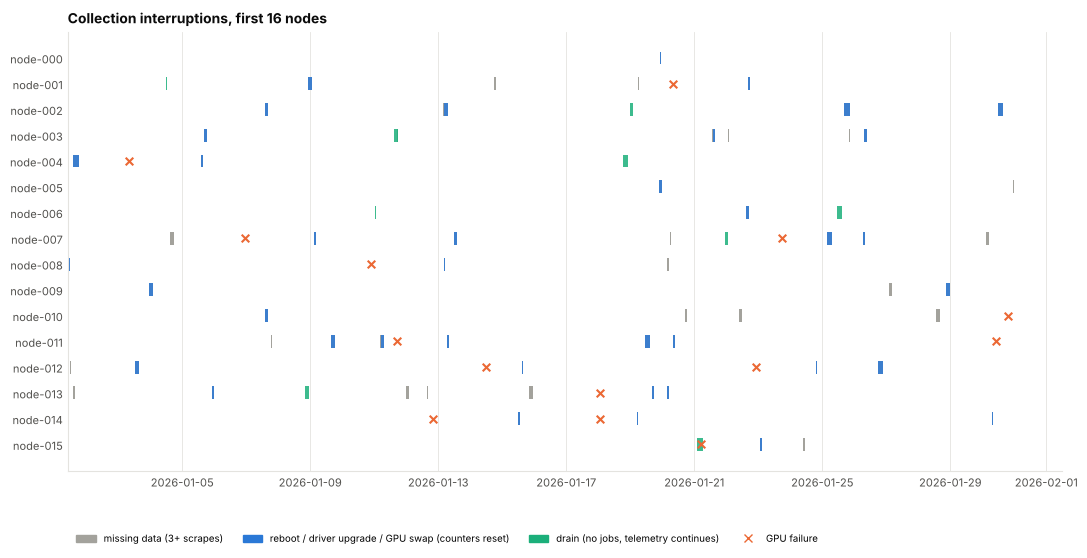

In [5]:
fig_collection(ds)
plt.show()

Takeaways for feature building:

- **Never difference raw counters.** Use `counter_increments`, which treats a drop as a reset.
- **Align before comparing GPUs across nodes.** `align_timestamps` snaps scrapes to the 5-minute grid.
- **Missing data is not zero.** Rolling features need to know how many scrapes they actually saw.

## 2. Warning signs by failure mode

Each panel aligns every failed GPU on its failure time and shows the signal for that mode over
the week before. The grey band is the healthy range (1st to 99th percentile over all healthy
GPU-hours).

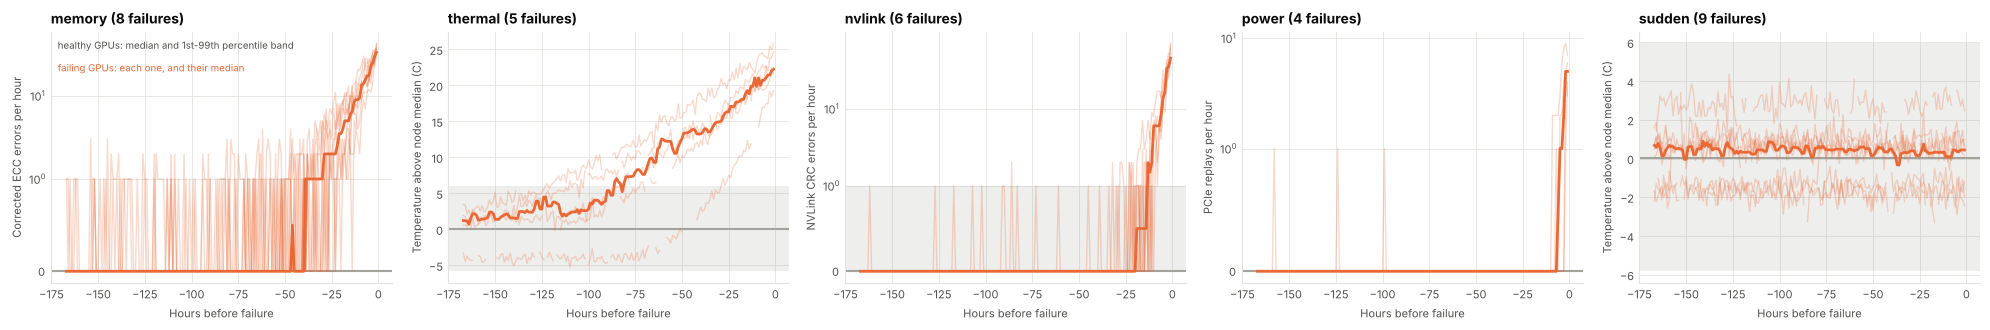

In [6]:
sig = scrape_signals(ds.telemetry, ds.step)
hourly = hourly_signals(sig)
fig_failure_signatures(hourly, ds.failures)
plt.show()

How early does each signal leave the healthy range? Below, the threshold is the 99.9th
percentile of healthy GPU-hours, and a warning needs two hours in a row above it. This uses the
known failure mode to pick the signal, so it is a ceiling for single-signal rules, not a model.

In [7]:
wt = warning_time(hourly, ds.failures)
wt.groupby("mode").agg(
    failures=("gpu_uuid", "size"),
    warned=("warning_hours", lambda x: int(x.notna().sum())),
    median_warning_h=("warning_hours", "median"),
    min_warning_h=("warning_hours", "min"),
    signal=("signal", "first"),
    threshold=("threshold", "first"),
)

,failures,warned,median_warning_h,min_warning_h,signal,threshold
mode,,,,,,
memory,8,8,22.5,12.0,sbe_per_h,2.00
nvlink,6,6,10.0,8.0,nvlink_per_h,2.00
power,4,3,5.0,2.0,pcie_per_h,1.00
sudden,9,0,NaN,NaN,temp_vs_node,8.45
thermal,5,5,67.0,22.0,temp_vs_node,8.45


- **thermal** gives the longest warning (days), because temperature drifts up slowly.
- **memory** shows up about a day ahead as corrected ECC errors accelerate.
- **nvlink** and **power** give hours, not days. A 24-hour horizon will miss part of their lead time,
  which is why the plan also has a 72-hour horizon and reports lead time per mode.
- **sudden** failures show nothing, by design. They set the floor on recall.

## 3. Look-alikes: why one signal is not enough

Some healthy GPUs log a steady trickle of corrected ECC errors, and jobs throw Xids all the time.
A rule like "any ECC error" or "any Xid" would page constantly.

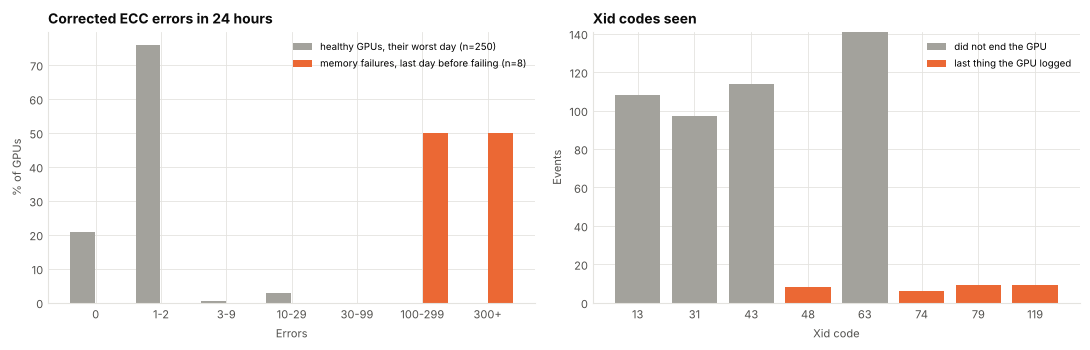

In [8]:
fig_lookalikes(hourly, sig, ds.failures)
plt.show()

- About 3% of healthy GPUs reach 10-29 corrected errors on their worst day, so the
  threshold has to sit above that. Memory failures sit at 100+ on their last day, so a rate
  threshold separates them well on simulated data. Real fleets will be less clean.
- Xids 13, 31 and 43 are application faults and almost never end a GPU. Xid 63 (row remapping)
  happens on healthy GPUs too, but a burst of them is a memory warning. 48, 74, 79 and 119 are the
  fatal codes, and they arrive at the moment of failure, so they are labels, not features.

## 4. Stragglers

Step time relative to the GPU's node peers, against SM clock relative to peers.

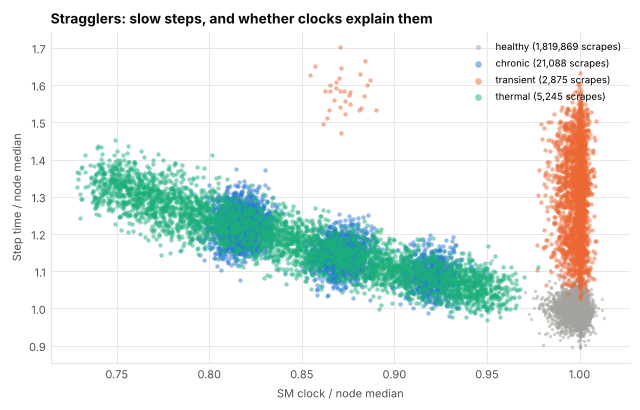

In [9]:
fig_stragglers(sig, ds.stragglers)
plt.show()

- **Transient** stragglers (host or network hiccups) are slow while their clocks look normal:
  the vertical streak at clock = 1.0. GPU telemetry alone cannot explain them, so the straggler
  detector needs step time.
- **Chronic** and **thermal** stragglers sit on the same diagonal: lower clocks, slower steps.
  Telling them apart needs temperature (thermal ones run hot) and history (chronic ones were
  always slow).
- Healthy GPUs stay within about ±5% of their peers.

## What this means for week 3

| Feature family | Why |
| --- | --- |
| Counter rates over 1h, 6h, 24h (from `counter_increments`) | ECC, NVLink and PCIe rates separate failing GPUs; totals do not |
| Rate acceleration (6h rate vs 24h rate) | Memory and NVLink failures accelerate; noisy healthy GPUs stay flat |
| Temperature, clock and power vs node median | Removes workload and rack effects, leaves the GPU's own drift |
| Temperature trend over 24h and 72h | Thermal failures drift for days |
| Count of Xid 63 in 24h | Burst of row remaps is a memory warning |
| Scrapes seen in window | Gaps must not look like "no errors" |

Labels: a row is positive if the GPU fails within 24h (and separately 72h) after it, using only
rows strictly before the failure row.